# Linear Regression with a Polynomial expansion

This code is to help us visualize the linear models for polynomials. <br>

This tutorial can be deployed in
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ChemAI-Lab/Math4Chem/blob/main/website/Lecture_Notes/Notes/Coding/polynomial_regression_overfitting.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
import matplotlib.tri as tri

In [2]:
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score

In [3]:
# generate random data over f(x) = sin(x) + x - 1
def get_data(N, bool_biased=True):
    # This creates an array x of N linearly spaced values between -1 and 1.
    # bool_biased: if True, adds a bias term (column of ones) to the input data X

    x = np.linspace(-1., 1., N) + np.random.uniform(low=-.1, high=.1, size=N)
    y = 1.2*np.sin(2*x) + x - 1.
    # Adds random noise to each y value.
    y = y + np.random.uniform(low=-.35, high=.35, size=x.shape)
    if bool_biased:
        X = np.column_stack((np.ones_like(x), x))
    else:
        X = x[:, None]
    return X, y

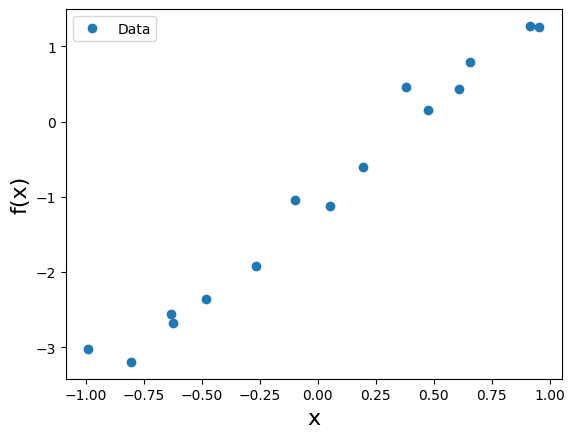

In [4]:
X, y = get_data(15, bool_biased=True)

plt.plot(X[:,1],y,'o', label='Data')
plt.xlabel('x',fontsize=16)
plt.ylabel('f(x)', fontsize=16)
plt.legend()

## Recap: Linear Regression
**Mean Square Error**
$$
{\cal L}(\mathbf{w}) = \frac{1}{2n} \left (\mathbf{y} - \mathbf{X}\mathbf{w} \right)^\top \left (\mathbf{y} - \mathbf{X}\mathbf{w} \right)
$$

**Gradient of a function equal to zero**  
$$
    \nabla {\cal L}(\mathbf{w}) \Big\rvert_{\mathbf{w}^{*}} = \frac{1}{2n} \nabla_{\mathbf{w}} \left [ \left (\mathbf{y} - \mathbf{X}\mathbf{w} \right)^\top \left (\mathbf{y} - \mathbf{X}\mathbf{w} \right) \right ]= 0
$$

To solve for $\mathbf{w}^*$, let's expand $ \left (\mathbf{y} - \mathbf{X}\mathbf{w} \right)^\top \left (\mathbf{y} - \mathbf{X}\mathbf{w} \right)$,

$$
    \left (\mathbf{y} - \mathbf{X}\mathbf{w} \right)^\top \left (\mathbf{y} - \mathbf{X}\mathbf{w} \right) = \mathbf{y}^\top \mathbf{y}  - \mathbf{y}^\top \mathbf{X}\mathbf{w} -  \mathbf{w}^\top\mathbf{X}^\top\mathbf{y} +   \mathbf{w}^\top\mathbf{X}^\top \mathbf{X}\mathbf{w}
$$
$$
    \nabla_{\mathbf{w}} {\cal L}(\mathbf{w}) = \frac{1}{2n}\left(  -2 \mathbf{X}^\top\mathbf{y} + 2\mathbf{X}^\top\mathbf{X}\mathbf{w} \right) = 0
$$

**Optimal parameters**

$$
 \mathbf{w}^* = \left ( \mathbf{X}^\top \mathbf{X} \right ) ^{-1} \mathbf{X}^\top \mathbf{y}
$$

**Old Notes** <br>
 Least Square:  [![Download PDF](https://img.shields.io/badge/Download_PDF-Click_Here-blue.svg)](https://github.com/ChemAI-Lab/Math4Chem/raw/main/website/Lecture_Notes/Notes/Linear_Regression.pdf)  <br>

**Extra:**
1. Homework, Proof the above equations.
2. [Equations from Sections 2.4.1 and 2.4.2](https://www2.imm.dtu.dk/pubdb/edoc/imm3274.pdf)

In [ ]:
# trining a linear model
def linear_model_solver(X, y):
    Xt =  # transpose of X
    A =  # A = X^T X
    z =  # z = X^T y
    A_inv =  # inverse of A
    w_opt = # w = A^-1 z
    return w_opt  # optimal parameters

## Coefficient of determination
$R^2$ is a statistical measure of how well the regression line fits the data.
1. $R^2= 1$, The model perfectly predicts the dependent variable. All data points fall on the regression line.
2. $R^2= 0$, The model is no better than just using the mean of the dependent variable to predict values. The independent variable(s) do not explain any of the variance.
3. $R^2=0.80$ means that \(80\%\) of the variability in the dependent variable is explained by the independent variable(s) in the model. The remaining \(20\%\) is unexplained.

$$
R^2 = 1 - \frac{SS_{res}}{SS_{tot}},
$$
where
$$
SS_{res} = \sum_i^n (\underbrace{\hat{y}_i}_{\text{true value}} - \underbrace{(\mathbf{w}^\top \mathbf{x}_i)}_{f(x_i)})^2
$$
$$
SS_{tot} =  \sum_i^n \left(\hat{y}_i - \bar{y} \right)^2, \quad \quad \text{where} \quad \quad \bar{y} = \frac{1}{n} \sum_i^n \underbrace{y_i}_{f(x_i)}.
$$

**Homework**<br>
Code $R^2$ as a function of $X,y$ and $\mathbf{w} = [a,b]$.

```Python
def r2_function(X,y_true,w):
    n = X.shape[0]
    y_pred =  # prediction

    y_bar =
    SS_tot =
    SS_res =

    r2_value =
    return r2_value

```

In [6]:
# find the optimal parameters
# Inline implementation of the linear model solver to avoid undefined name errors
Xt = X.T
A = Xt @ X
z = Xt @ y
A_inv = np.linalg.inv(A)
w_opt = A_inv @ z

print("Optimal parameters")
print(w_opt)

y_data_pred = X @ w_opt
r2_value = r2_score(y, y_data_pred)
print(f'R-squared score: {r2_value:.2f}')

Optimal parameters
[-0.9992404  2.4889345]
R-squared score: 0.98


Grid with bias:  (100, 2)


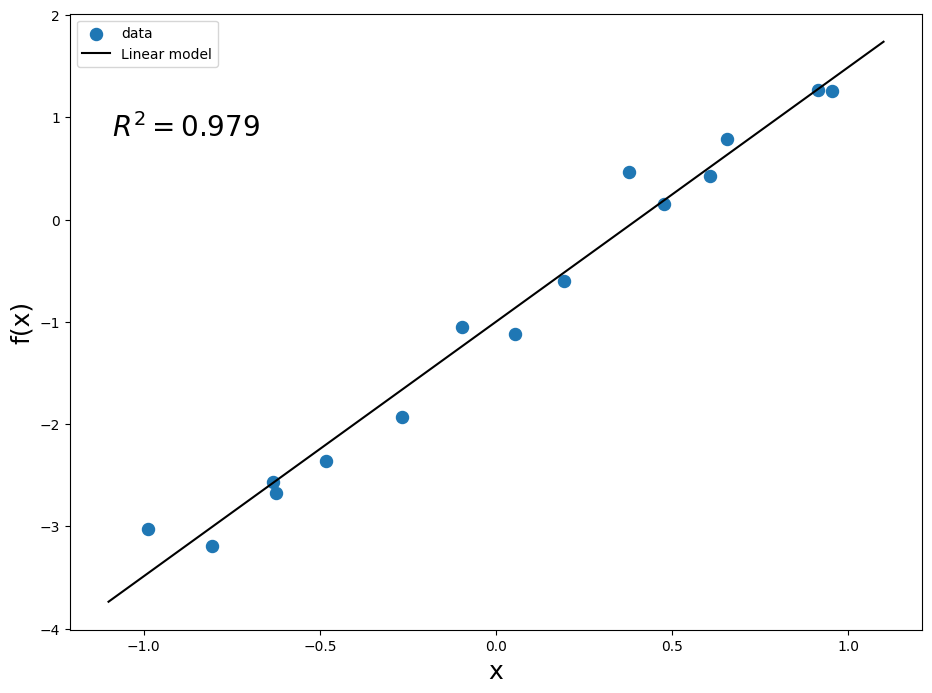

In [7]:
# plot our model
x_grid = np.linspace(-1.1,1.1,100)
X_grid = np.column_stack((np.ones_like(x_grid),x_grid) ) # add bias term
print("Grid with bias: ",X_grid.shape)
y_pred = X_grid@w_opt

# plot the data
fig, ax = plt.subplots(figsize=(11, 8))
ax.text(0.05,0.8,r'$R^2 = $' + f'{r2_value:0.3f}',transform=ax.transAxes,fontsize=20)
ax.scatter(X[:, 1], y, label='data', s=75)
ax.plot(X_grid[:, 1], y_pred, c='k',label='Linear model', markersize=5)
ax.set_xlabel('x',fontsize=18)
ax.set_ylabel('f(x)', fontsize=18)
plt.legend()

# Beyond Linear Models


Let's revise polynomials:

How many terms if we have a second-order polynomial and $d=3$?
$$
\begin{align}
(1+x_1+x_2+x_3)^3 &= (1+x_1+x_2+x_3)(1+x_1+x_2+x_3)^2 \\
&= 1+3x_1+3x^2_1+x^3_1+3x_2+6x_1x_2+3x^2_1x_2 \\
& +3x_2^2+3x_1x_2^2+x_2^3 +3x_3+6x_1x_3+3x_1^2x_3 \\
& +6x_2x_3+6x_1x_2x_3+3x_2^2x_3+3x_3^2 \\
& +3x_1x_3^2+3x_2x_3^2+x_3^3
\end{align}
$$

This is simply a new representation of $x$
$$
\phi(\mathbf{x}) = [1, x_1, x_2, x_3, \cdots, x_i x_j, \cdots, x_i^{ m} x_j^{p}, \cdots, x_i^{ m} x_j^{p}x_{\ell}^{r}]
$$

## Linear models on basis-set expansion

$$
    f(\mathbf{x},\mathbf{w}) = \sum_{i=0}^d w_i \phi(\mathbf{x}) = \mathbf{w}^\top \phi(\mathbf{x})
$$


* **Loss function**,
$$
    \begin{align}
    {\cal L}(\mathbf{w}) &= \frac{1}{2n}\sum_i^N (y_i - f(\mathbf{x}_i,\mathbf{w}))^2 = \frac{1}{2}\sum_i^N (y_i - \mathbf{w}^\top \phi(\mathbf{x}_i))^2 \\
    &= \frac{1}{2n} \left (\mathbf{y} - \Phi(\mathbf{X})\mathbf{w} \right)^\top \left (\mathbf{y} -  \Phi(\mathbf{X})\mathbf{w} \right)
    \end{align}
$$
Homework, proof the above equations.


1. What is $\Phi(\mathbf{x})$?
2. What is the form of the **optimal** parameters $\mathbf{w}^*$?


<!-- **What is $\Phi(\mathbf{x})$?**<br>
Let's assume a third order polynomial,
$$
\phi(x) = [x^0,x^1,x^2,x^3] = \underbrace{[1,x,x^2,x^3]}_{p\,\, \text{elemets}}
$$
If we consider 3 points,
$$
\Phi(\mathbf{X}) = \underbrace{\begin{pmatrix}
\phi(x_1)^\top  \\
\vdots \\
\phi(x_N)^\top \\
\end{pmatrix}}_{(N,p)} = \begin{pmatrix}
1 & x_1^1 & x^2_1 & x^3_1 \\
1 & x_2^1 & x^2_2 & x^3_2 \\
\vdots & & \cdots & \vdots \\
1 & x_N^1 & x^2_N & x^3_N \\
\end{pmatrix}
$$

**Derive the equations for $\mathbf{w}^*$**:

$$
\underbrace{\mathbf{w}^*}_{(p,1)} = \left ( \Phi(\mathbf{X})^\top \Phi(\mathbf{X}) \right ) ^{-1} \Phi(\mathbf{X})^\top \mathbf{y}

$$ -->


Instead of coding how to create the polynomial representation, we will use Sklearn. <br>
Read the documentation: [`PolynomialFeatures`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)

In [8]:
def polynomial_features(X, p):
    # transform the input data to polynomial features up to degree p
    poly = PolynomialFeatures(p)
    Phi = poly.fit_transform(X)
    return Phi

In [9]:
# x = np.ones((1,1))
x = np.random.normal(-1.,0.1,size=(1,1))
print(f'Original x \n{x}')
for p in range(1,4):
    x_phi = polynomial_features(x,p)
    print(f'For degree {p}, the polynomial features are: \n{x_phi}')

Original x 
[[-0.90908279]]
For degree 1, the polynomial features are: 
[[ 1.         -0.90908279]]
For degree 2, the polynomial features are: 
[[ 1.         -0.90908279  0.82643151]]
For degree 3, the polynomial features are: 
[[ 1.         -0.90908279  0.82643151 -0.75129467]]


In [11]:
# Define the solver function inline to resolve the NameError
def linear_model_solver(X, y):
    Xt = X.T
    A = Xt @ X
    z = Xt @ y
    A_inv = np.linalg.inv(A)
    w_opt = A_inv @ z
    return w_opt

# transform the training data to polynomial features
p = 3 # degree

X = X[:,-1:] # select the last column only (without bias term)

X_phi = polynomial_features(X, p)
print(X.shape, X_phi.shape)
w_phi_opt = linear_model_solver(X_phi, y)
print(f'Optimal parameters: \n{w_phi_opt}')

y_data_phi_pred = X_phi@w_phi_opt
r2_score_poly = r2_score(y, y_data_phi_pred)
print(f'R2 polynomial model: {r2_score_poly:.3f}')

(15, 1) (15, 4)
Optimal parameters: 
[-1.05591772  2.96766371  0.14678663 -0.74353342]
R2 polynomial model: 0.987


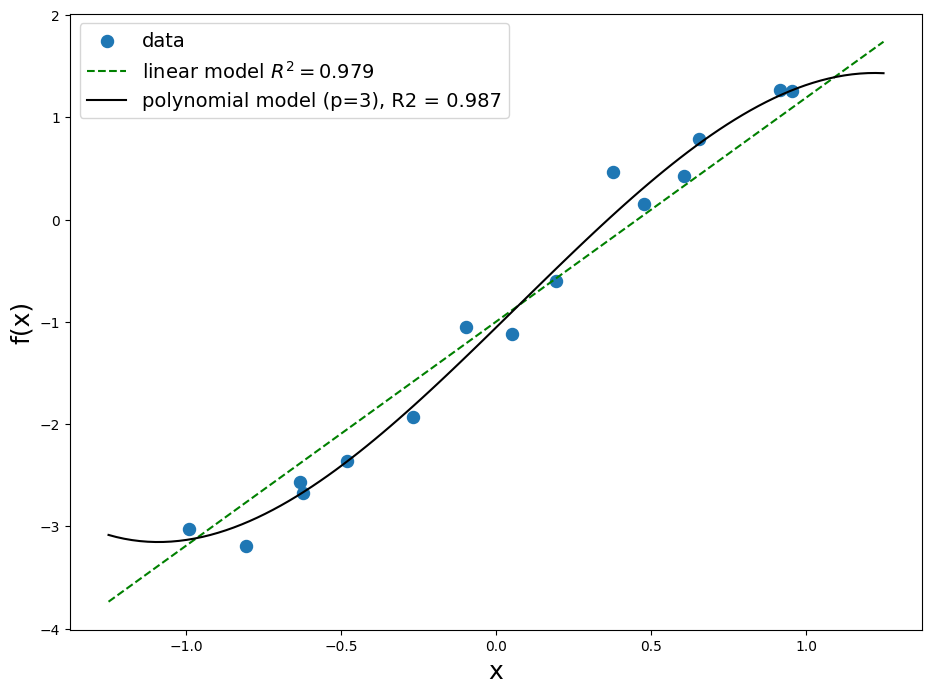

In [12]:
X_grid = np.linspace(-1.25,1.25,100)
X_grid = X_grid[:,None]

X_grid_phi = polynomial_features(X_grid, p)
y_pred_phi = X_grid_phi@w_phi_opt

# plot the data and the polynomial model
fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(X[:, 0], y, label='data', s=75)
ax.plot(X_grid[:, 0], y_pred, c='green', ls = '--',
        label='linear model ' + r'$R^2 = $' +
        f'{r2_value:0.3f}', markersize=5)
ax.plot(X_grid[:, 0], y_pred_phi, c='k',
        label=f'polynomial model (p={p}), R2 = {r2_score_poly:.3f}', markersize=5)
ax.set_xlabel('x',fontsize=18)
ax.set_ylabel('f(x)', fontsize=18)
plt.legend(fontsize=14)

degree: 2, R2= 0.9795
degree: 4, R2= 0.9868
degree: 6, R2= 0.9880
degree: 8, R2= 0.9886
degree: 10, R2= 0.9913


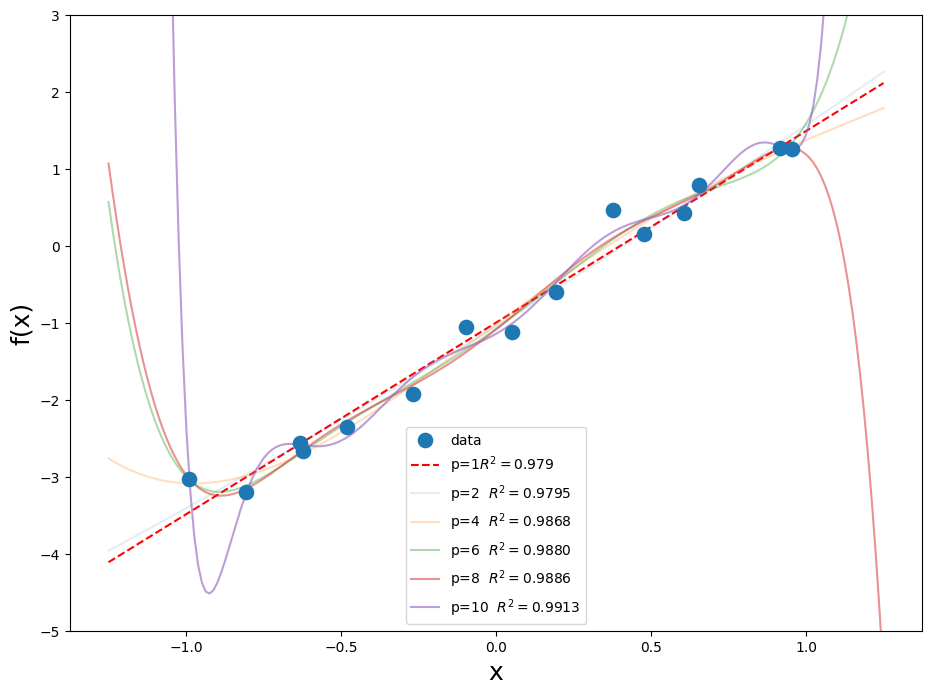

In [14]:
# R2 as a function of the polynomial degree

# linear model
X_grid = np.linspace(-1.25, 1.25, 200)
X_grid = X_grid[:, None]
X_grid_w_bias = np.column_stack((np.ones_like(X_grid), X_grid)) # check this
y_pred = X_grid_w_bias @ w_opt

fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(X[:, 0], y, label='data', s=105,zorder=4)
ax.plot(X_grid[:, 0], y_pred, c='red', ls='--',
        label='p=1' + r'$R^2 = $' +
        f'{r2_value:0.3f}', markersize=5)

for p in range(2,11,2):# loop over polynomial degrees p = [2, 4, .., 10]
    X_phi = polynomial_features(X, p)
    w_phi_opt = linear_model_solver(X_phi, y) # we can reuse our function
    # print(f'Optimal parameters\n{w_phi_opt}')

    y_data_phi_pred = X_phi@w_phi_opt
    r2_score_poly = r2_score(y, y_data_phi_pred)
    print(f'degree: {p}, R2= {r2_score_poly:.4f}')

    X_grid_phi = polynomial_features(X_grid, p)
    y_pred_phi = X_grid_phi@w_phi_opt
# plot the data and the polynomial model

    ax.plot(X_grid[:, 0], y_pred_phi,
            label=f'p={p} ' +  r' $R^2 = $' +
            f'{r2_score_poly:0.4f}',  markersize=5, alpha=0.95*p/15)
ax.set_xlabel('x', fontsize=18)
ax.set_ylabel('f(x)', fontsize=18)
ax.set_ylim(-5,3)
plt.legend(fontsize=10,loc=0)

## The Challenge of Overfitting

- **Risk in Flexibility**:  Higher-degree polynomials might fit the training data too precisely, capturing noise rather than the underlying trend, a phenomenon known as overfitting.
- **Consequences**: An overfitted model performs poorly on new, unseen data, rendering it less effective for predictive purposes.

<br>


>#### **Learn More:**
1. **What is Overfitting**: [Educational Resource](https://www.v7labs.com/blog/overfitting)
2. **Regularization in Machine Learning (with Code Examples)**: [Example Application](https://www.dataquest.io/blog/regularization-in-machine-learning/)
3. **Polynomial Regression**: [Educational Resource](https://medium.com/analytics-vidhya/polynomial-regression-%EF%B8%8F-e0e20bfbe9d5)